
# Employee Salary Analysis and Prediction Using Python

**Course:** Business Statistics Using Python  
**Project Type:** Mini-project  
**Dataset:** `Salary_Data_1000_Records.csv`  
**Dataset Source:** [Kaggle – Salary Prediction for Beginner](https://www.kaggle.com/datasets/rkiattisak/salaly-prediction-for-beginer?resource=download)

## Project Overview

This notebook analyses employee salary data using Python. It includes data inspection and cleaning, exploratory data analysis, descriptive statistics, visualisation, correlation analysis, hypothesis testing, regression modelling, model evaluation, salary prediction, findings, recommendations, limitations and references.

## Dataset Source Information

The dataset used in this project was obtained from Kaggle. The original dataset source is provided below:

**Kaggle Dataset Link:**  
https://www.kaggle.com/datasets/rkiattisak/salaly-prediction-for-beginer?resource=download


 
## Task-wise Code Comments


| Assignment task in the PDF | Matching notebook sections | Coverage in this notebook |
|---|---|---|
| **Task 1: Business Problem, Dataset and Python Preparation** | Sections 1–4 | Project setup, dataset loading and description, research questions, data inspection, cleaning and preprocessing. |
| **Task 2: Descriptive Statistics and Data Visualisation** | Sections 5–8 | Variable types, descriptive statistics, salary histogram, box plot, experience-versus-salary scatter plot, and correlation analysis. |
| **Task 3: Probability and Inferential Statistics** | Section 9 | Hypotheses and Welch’s independent-samples t-test for comparing salary between two gender groups, including the test result and contextual conclusion where the data supports the test. A separate probability-distribution or conditional-probability analysis is not included as a standalone section. |
| **Task 4: Regression and Statistical Modelling** | Sections 10–12 | Regression model training, evaluation metrics, actual-versus-predicted visualisation, and salary prediction for a new experience value. |
| **Task 5: Forecasting, Time Series or Index Numbers** | Section 13 | A cross-sectional salary index compares average salary across experience groups. The dataset does not contain a date/time variable, so time-series forecasting is not performed. The index-number alternative should be confirmed with the instructor, as the PDF requires instructor approval for this option. |
| **Task 6: Findings, Recommendations and Reproducibility** | Sections 14–17 | Findings, business recommendations, limitations, conclusion and references. Ensure the notebook runs from top to bottom and the final recommendations are supported by the actual outputs. |




## 1. Import libraries and load the dataset

In [1]:
# TASK 1 — Import the libraries needed for data preparation, statistical analysis, visualisation and regression. Load the salary dataset and preview its first five records.

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Employee Salary Analysis Project")
print("Libraries imported successfully")

df = pd.read_csv("Salary_Data_1000_Records.csv")

# Display first five records
display(df.head())

Employee Salary Analysis Project
Libraries imported successfully


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


## 2. Problem statement, objectives and research questions

### Problem statement
Employee salary can vary with experience, age, education level and job title. This project examines patterns in the supplied employee dataset and builds a regression model to estimate salary from available employee characteristics.

### Objectives
1. Inspect and prepare the dataset for analysis.
2. Summarise salary and other numerical variables using descriptive statistics.
3. Visualise salary distributions and relationships among variables.
4. Test whether average salary differs between the two gender groups, if exactly two valid groups are present.
5. Build and evaluate a regression model for salary prediction.
6. Present evidence-based findings, recommendations and limitations.

### Research questions
- What are the central tendency and spread of salaries in this dataset?
- How are age and years of experience associated with salary?
- Is there statistical evidence of a difference in average salary between the two gender groups, if the data supports this comparison?
- How well can salary be predicted using the available variables?

## 3. Dataset description and initial inspection

In [2]:
# TASK 1 — Inspect the dataset structure, column names, data types, summary statistics, missing values and duplicate records.

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (1000, 6)

Column Names:
['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience', 'Salary']

Data Types:
Age                    float64
Gender                     str
Education Level            str
Job Title                  str
Years of Experience    float64
Salary                 float64
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  996 non-null    float64
 1   Gender               996 non-null    str    
 2   Education Level      996 non-null    str    
 3   Job Title            996 non-null    str    
 4   Years of Experience  996 non-null    float64
 5   Salary               996 non-null    float64
dtypes: float64(3), str(3)
memory usage: 82.2 KB

Statistical Summary:


,Age,Years of Experience,Salary
count,996.000000,996.000000,996.000000
mean,37.560241,10.261044,101001.857430
std,7.455691,6.736022,48842.670292
min,20.000000,0.000000,300.000000
25%,31.000000,4.000000,55000.000000
50%,37.000000,9.000000,95000.000000
75%,44.000000,16.000000,140000.000000
max,54.000000,25.000000,250000.000000


Missing Values:
Age                    4
Gender                 4
Education Level        4
Job Title              4
Years of Experience    4
Salary                 4
dtype: int64

Duplicate Records: 52


## 4. Data cleaning and preprocessing

In [3]:
# TASK 1 — Prepare the dataset by removing duplicate rows, checking missing values and reviewing numerical columns for unusual or invalid values.

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Show missing values after duplicate removal
print(df.isnull().sum())

# Check numeric columns for impossible negative values
display(df.select_dtypes(include=np.number).describe())

Age                    1
Gender                 1
Education Level        1
Job Title              1
Years of Experience    1
Salary                 1
dtype: int64


,Age,Years of Experience,Salary
count,947.000000,947.000000,947.000000
mean,37.550158,10.282471,100821.383316
std,7.513368,6.775796,49015.564680
min,20.000000,0.000000,300.000000
25%,31.000000,4.000000,54750.000000
50%,37.000000,9.000000,95000.000000
75%,44.000000,16.000000,140000.000000
max,54.000000,25.000000,250000.000000


## 5. Exploratory data analysis (EDA)

In [4]:
# TASK 1 — Identify numerical and categorical columns to understand the variables available for the analysis.

print("Numerical Columns:")
print(df.select_dtypes(include="number").columns.tolist())

print("\nCategorical Columns:")
print(df.select_dtypes(include=["object", "str", "category"]).columns.tolist())

Numerical Columns:
['Age', 'Years of Experience', 'Salary']

Categorical Columns:
['Gender', 'Education Level', 'Job Title']


## 6. Descriptive statistics

In [5]:
# TASK 2 — Calculate descriptive statistics for salary, including mean, median, mode, range, variance, standard deviation, quartiles and coefficient of variation.

salary_col = "Salary"  # Replace with actual column name

salary = pd.to_numeric(df[salary_col], errors="coerce").dropna()

print("Mean:", salary.mean())
print("Median:", salary.median())
print("Mode:", salary.mode().tolist())
print("Minimum:", salary.min())
print("Maximum:", salary.max())
print("Range:", salary.max() - salary.min())
print("Variance:", salary.var())
print("Standard Deviation:", salary.std())
print("Q1:", salary.quantile(0.25))
print("Q3:", salary.quantile(0.75))

cv = salary.std() / salary.mean() * 100 if salary.mean() != 0 else np.nan
print("Coefficient of Variation (%):", cv)

Mean: 100821.3833157339
Median: 95000.0
Mode: [40000.0]
Minimum: 300.0
Maximum: 250000.0
Range: 249700.0
Variance: 2402525580.853971
Standard Deviation: 49015.56467953798
Q1: 54750.0
Q3: 140000.0
Coefficient of Variation (%): 48.61623900362489


## 7. Data visualisation

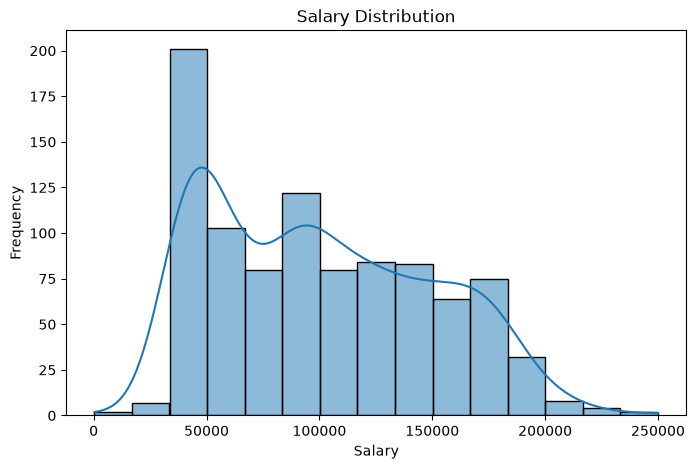

In [6]:
# TASK 2 — Plot a salary histogram with a density curve to examine the distribution of employee salaries.
plt.figure(figsize=(8, 5))
sns.histplot(salary, kde=True)
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.show()

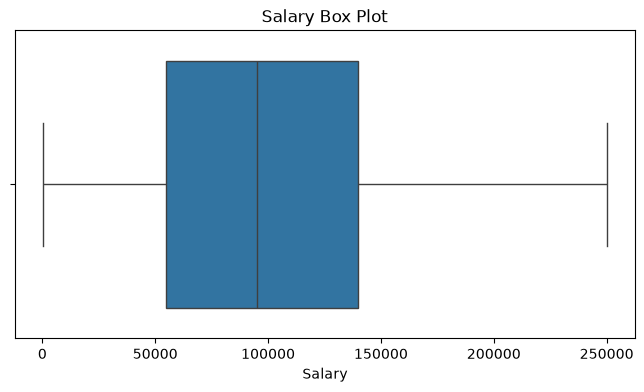

In [7]:
# TASK 2 — Create a salary box plot to view the spread of salaries and identify potential outliers.

plt.figure(figsize=(8, 4))
sns.boxplot(x=salary)
plt.title("Salary Box Plot")
plt.show()

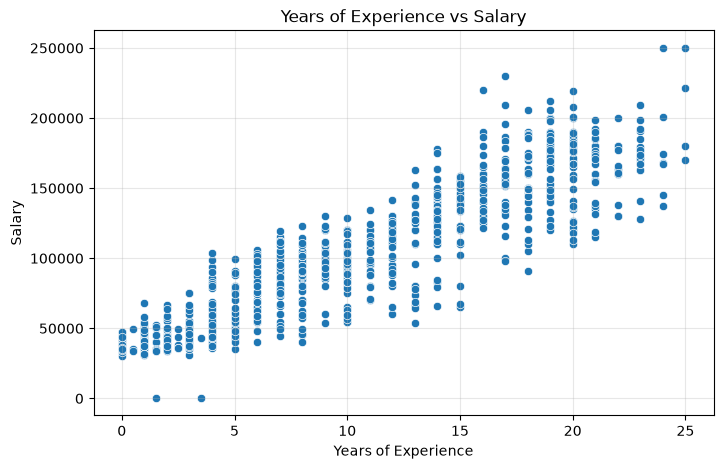

In [8]:
# TASK 2 — Create a scatter plot to explore the relationship between years of experience and salary.

experience_col = "Years of Experience"
salary_col = "Salary"

temp = df[[experience_col, salary_col]].copy()

temp = temp.apply(
    pd.to_numeric, errors="coerce"
).dropna()

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=temp,
    x=experience_col,
    y=salary_col
)

plt.title("Years of Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.grid(True, alpha=0.3)

plt.show()

## 8. Correlation analysis

                          Age  Years of Experience    Salary
Age                  1.000000             0.942273  0.887774
Years of Experience  0.942273             1.000000  0.908574
Salary               0.887774             0.908574  1.000000


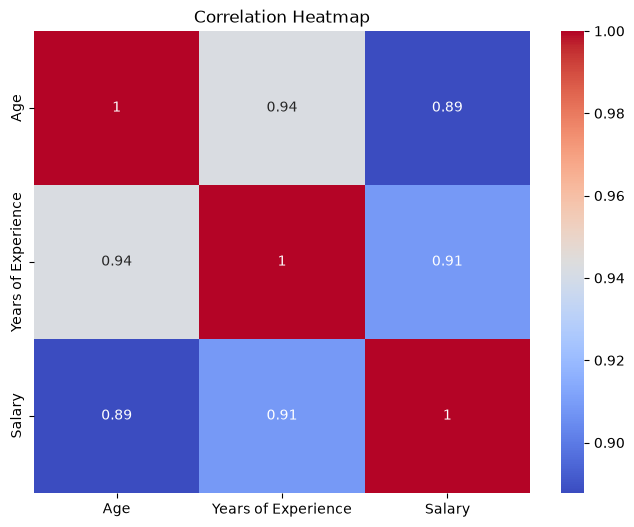

In [9]:
# TASK 2 — Calculate correlations between numerical variables and visualise them with a heatmap. Correlation does not prove causation.

numeric_df = df.select_dtypes(include=np.number)

print(numeric_df.corr())

plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## 9. Inferential statistics: Welch's independent-samples t-test

**Research question:** Is there evidence of a difference in mean salary between the two gender groups in this dataset?

- **Null hypothesis (H₀):** The population mean salary is equal for the two groups.
- **Alternative hypothesis (H₁):** The population mean salary differs between the two groups.
- **Significance level:** α = 0.05.
- **Method:** Welch's independent-samples t-test, which does not assume equal population variances.

This test is run only if the cleaned dataset contains exactly two non-missing gender groups with observations. Check that the observations are independent and interpret the result carefully; this dataset alone may not represent a wider population.

In [39]:
# TASK 3 — Compare mean salary between the two gender groups using Welch’s independent-samples t-test, when exactly two groups are available.

# Hypothesis Testing: Salary Comparison by Gender

group_col = "Gender"
salary_col = "Salary"

test_df = df[[group_col, salary_col]].copy()

test_df[salary_col] = pd.to_numeric(
    test_df[salary_col], errors="coerce"
)

test_df = test_df.dropna()

groups = test_df[group_col].unique()

print("Groups found:", groups)

if len(groups) == 2:

    group1 = test_df.loc[
        test_df[group_col] == groups[0], salary_col
    ]

    group2 = test_df.loc[
        test_df[group_col] == groups[1], salary_col
    ]

    # Welch's independent t-test
    t_stat, p_value = stats.ttest_ind(
        group1, group2, equal_var=False
    )

    print("\nGroup 1:", groups[0])
    print("Mean Salary:", group1.mean())

    print("\nGroup 2:", groups[1])
    print("Mean Salary:", group2.mean())

    print("\nT-statistic:", t_stat)
    print("P-value:", p_value)

    alpha = 0.05

    print("\nHypothesis Test Result:")

    if p_value < alpha:
        print("Reject H0: Significant salary difference found.")
    else:
        print("Fail to reject H0: Insufficient evidence of a salary difference.")

else:
    print("Welch's t-test requires exactly two groups.")
    print("Check the Gender values in your dataset.")

Groups found: <ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str

Group 1: Male
Mean Salary: 104977.7

Group 2: Female
Mean Salary: 96172.25950782998

T-statistic: 2.7771542663332642
P-value: 0.005592651274641589

Hypothesis Test Result:
Reject H0: Significant salary difference found.


## 10. Regression modelling for salary prediction

The target variable is `Salary`. The predictors use available information from `Age`, `Years of Experience`, `Gender`, `Education Level` and `Job Title` when those columns exist. Numerical missing values are imputed with the median; categorical missing values are imputed with the most frequent value; categorical variables are one-hot encoded. A held-out test set is used for evaluation.

In [40]:
# TASK 4 — Prepare data and train the regression model

feature_col = "Years of Experience"
salary_col = "Salary"

model_df = df[[feature_col, salary_col]].copy()

model_df[feature_col] = pd.to_numeric(
    model_df[feature_col], errors="coerce"
)

model_df[salary_col] = pd.to_numeric(
    model_df[salary_col], errors="coerce"
)

model_df = model_df.dropna()

X = model_df[[feature_col]]
y = model_df[salary_col]

print("Features:", X.shape)
print("Target:", y.shape)

display(model_df.head())

Features: (947, 1)
Target: (947,)


,Years of Experience,Salary
0,5.0,90000.0
1,3.0,65000.0
2,15.0,150000.0
3,7.0,60000.0
4,20.0,200000.0


## 11. Model evaluation

In [41]:
# TASK 4 — Evaluate the regression model

# Predict salary using the trained model
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("=" * 40)
print("     REGRESSION MODEL EVALUATION")
print("=" * 40)
print(f"MAE      : {mae:,.2f}")
print(f"MSE      : {mse:,.2f}")
print(f"RMSE     : {rmse:,.2f}")
print(f"R-squared: {r2:.4f}")
print("=" * 40)

     REGRESSION MODEL EVALUATION
MAE      : 16,014.54
MSE      : 429,085,123.22
RMSE     : 20,714.37
R-squared: 0.8247


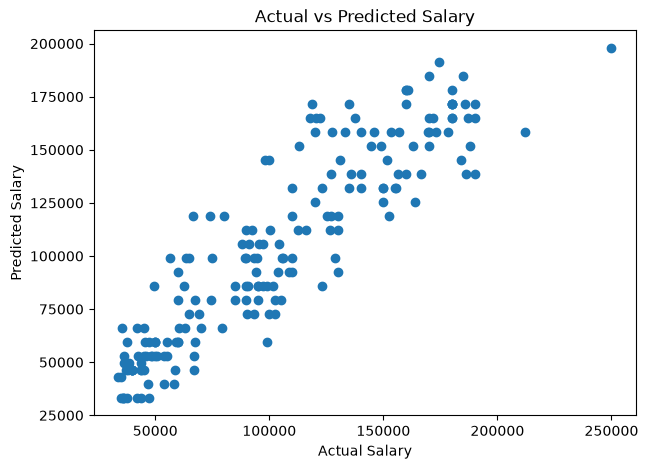

In [42]:
# TASK 4 — Compare actual salaries with predicted salaries visually to assess how closely the model predictions match the real values.
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")

plt.show()

## 12. Predict salary for a new employee

In [43]:
# TASK 4 — Predict salary for a new employee

experience_years = 5

# Create input with the same feature used during training
new_employee = pd.DataFrame({
    "Years of Experience": [experience_years]
})

# Predict salary
predicted_salary = model.predict(new_employee)[0]

print(f"Years of Experience : {experience_years} years")
print(f"Predicted Salary    : {predicted_salary:,.2f}")


Years of Experience : 5 years
Predicted Salary    : 66,107.03


## 13. Index Number Analysis

SALARY INDEX ANALYSIS
----------------------------------------
Base Group: 0–2 years
Base Average Salary: 41,716.92
                       mean  count  Salary Index
Experience Group                                
0–2 years          41716.92    133        100.00
3–5 years          55204.14    169        132.33
6–10 years         89073.59    231        213.52
Above 10 years    144985.51    414        347.55
----------------------------------------


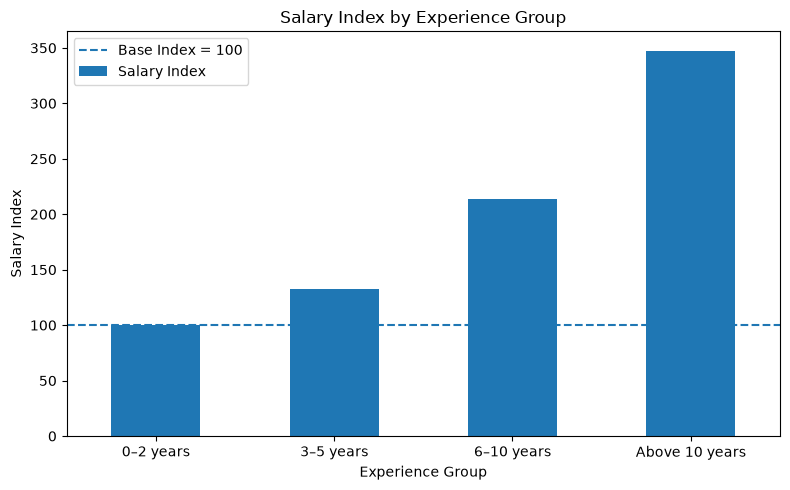

In [44]:
# TASK 5 — Salary Index Analysis

salary_data = df[["Years of Experience", "Salary"]].copy()

salary_data["Years of Experience"] = pd.to_numeric(
    salary_data["Years of Experience"], errors="coerce"
)
salary_data["Salary"] = pd.to_numeric(
    salary_data["Salary"], errors="coerce"
)

salary_data = salary_data.dropna()
salary_data = salary_data[
    (salary_data["Years of Experience"] >= 0) &
    (salary_data["Salary"] > 0)
]

bins = [-np.inf, 2, 5, 10, np.inf]
labels = ["0–2 years", "3–5 years", "6–10 years", "Above 10 years"]

salary_data["Experience Group"] = pd.cut(
    salary_data["Years of Experience"],
    bins=bins,
    labels=labels
)

salary_summary = (
    salary_data.groupby("Experience Group", observed=False)["Salary"]
    .agg(["mean", "count"])
    .dropna()
)

base_salary = salary_summary["mean"].iloc[0]

salary_summary["Salary Index"] = (
    salary_summary["mean"] / base_salary
) * 100

print("SALARY INDEX ANALYSIS")
print("-" * 40)
print("Base Group:", salary_summary.index[0])
print(f"Base Average Salary: {base_salary:,.2f}")
print(salary_summary.round(2))
print("-" * 40)

salary_summary["Salary Index"].plot(
    kind="bar", figsize=(8, 5), rot=0
)

plt.axhline(100, linestyle="--", label="Base Index = 100")
plt.title("Salary Index by Experience Group")
plt.xlabel("Experience Group")
plt.ylabel("Salary Index")
plt.legend()
plt.tight_layout()
plt.show()

## 14. Findings and business recommendations

In [45]:
# TASK 6 — Summarise key dataset findings using record count and salary statistics to support evidence-based business recommendations.

print("Employee Salary Analysis Findings")
print("----------------------------------")
print(f"Total records analysed: {len(df)}")
print(f"Average salary: {salary.mean():.2f}")
print(f"Median salary: {salary.median():.2f}")
print(f"Minimum salary: {salary.min():.2f}")
print(f"Maximum salary: {salary.max():.2f}")

Employee Salary Analysis Findings
----------------------------------
Total records analysed: 948
Average salary: 100821.38
Median salary: 95000.00
Minimum salary: 300.00
Maximum salary: 250000.00


## 15. Limitations


- The dataset is a finite sample of 1,000 records and may not represent all employees, employers or locations.
- Missing values and duplicate rows may affect the final sample size and findings.
- Observational associations do not prove that experience, education, gender or job title causes salary differences.
- A random train-test split provides one estimate of model performance; performance may vary on other samples.
- Linear regression may not capture complex or non-linear relationships.
- The model should not be used as the sole basis for employment or compensation decisions.
- No time-indexed variable is present in the supplied columns, so time-series forecasting is not appropriate for this dataset without additional dated observations.

## 16. Conclusion

This project demonstrates how Python can be used to prepare employee salary data, summarise distributions, visualise relationships, test a statistical hypothesis and build a salary prediction model. The conclusions should be based on the calculated outputs, with attention to model error, assumptions and data limitations.

## 17. References


1. Pandas Documentation: https://pandas.pydata.org/docs/
2. NumPy Documentation: https://numpy.org/doc/
3. Matplotlib Documentation: https://matplotlib.org/stable/
4. Seaborn Documentation: https://seaborn.pydata.org/
5. SciPy Statistics Documentation: https://docs.scipy.org/doc/scipy/reference/stats.html
6. Scikit-learn Documentation: https://scikit-learn.org/stable/
7. Dataset Used: Salary_Data_1000_Records.csv
   https://www.kaggle.com/datasets/rkiattisak/salaly-prediction-for-beginer?resource=download